# Week 11 - Clustering 2, DBSCAN and Hierarchical Clustering
## Dataset: NOAA Storm Events

This week covers two more clustering methods, DBSCAN and hierarchical agglomerative clustering (HAC). Both avoid the main limits of k-means from Week 10, which needs the number of clusters in advance, assigns every point to some cluster, and favors round clusters of similar size.

DBSCAN (density-based spatial clustering of applications with noise) grows clusters wherever points are densely packed and labels points in sparse areas as noise. A point is a core point if at least `min_samples` points, counting itself, lie within a distance `eps` of it. Clusters are chains of core points within `eps` of each other, plus the points they reach, and everything else is noise. The number of clusters comes out of the data, and clusters can take any shape.

HAC starts with every point as its own cluster and repeatedly merges the two closest clusters until one remains. The linkage method defines the distance between two clusters, the closest pair of points (single linkage), the farthest pair (complete), the average over all pairs (average), or the increase in within-cluster variance caused by the merge (Ward). The merge history is drawn as a dendrogram, a tree whose branch heights show how far apart the merged clusters were, and cutting the tree at a height gives the clusters.

The notebook uses DBSCAN to rebuild storm systems from individual events in space and time and compares them with NOAA's storm episodes, then uses HAC to group the 36 most common event types by how they behave.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Data

The events are the same 31,863 used since Week 4, with a location, a start time, and a damage entry. NOAA groups events into episodes, and the median episode has 2 events, with 34% of episodes holding a single event. One fact matters for everything below. No episode contains events from more than one National Weather Service forecast office, so NOAA's episodes stop at office boundaries even when a storm does not.

In [2]:
begin = pd.to_datetime(df['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(df['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
df['begin'] = begin
df['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON', 'begin']).copy().reset_index(drop=True)
data['damaged'] = (data['damageProperty'] > 0).astype(int)
data['eastKm'] = data['BEGIN_LON'] * 111.32 * np.cos(np.radians(data['BEGIN_LAT']))
data['northKm'] = data['BEGIN_LAT'] * 110.57
data['hours'] = (data['begin'] - data['begin'].min()).dt.total_seconds() / 3600
print('Events with a location, a start time, and a damage entry:', len(data))
episode_size = data.groupby('EPISODE_ID').size()
print(f'Storm episodes: {len(episode_size)} | median events per episode: {episode_size.median():.0f} | '
      f'single-event episodes: {(episode_size == 1).mean():.3f}')
print(f'Episodes that involve more than one forecast office: {(data.groupby("EPISODE_ID")["WFO"].nunique() > 1).mean():.3f}')

Events with a location, a start time, and a damage entry: 31863
Storm episodes: 5220 | median events per episode: 2 | single-event episodes: 0.339
Episodes that involve more than one forecast office: 0.000


## Part A - DBSCAN in space and time

### A distance that mixes kilometers and hours

Two events belong to the same storm if they happen close together in both place and time, so DBSCAN works on three coordinates, kilometers east, kilometers north, and hours since the start of the year multiplied by a speed. The speed is the distance metric's exchange rate between time and space. At 25 km per hour, two events an hour apart at the same place are as far apart as two events 25 km apart at the same moment. The next cell tries speeds of 10, 25, and 50 km per hour with a grid of `eps` and `min_samples` values. It scores each result by its adjusted Rand index (ARI) with NOAA's episodes, counting every noise event as its own group, records how many clusters span more than one forecast office, and then draws the sorted k-distance plot at the best speed.


 km per hour  eps (km)  min_samples  Clusters  Noise share  ARI with NOAA episodes  Clusters spanning 2+ offices
          10        35            2      4471        0.215                   0.481                         0.124
          10        35            3      2636        0.330                   0.477                         0.177
          25        50            5      1242        0.439                   0.451                         0.288
          10        35            5      1300        0.511                   0.448                         0.236
          25        50            2      3997        0.182                   0.447                         0.150
          25        50            3      2435        0.280                   0.445                         0.212
          50        50            2      4423        0.231                   0.445                         0.125
          50        50            3      2552        0.348                   0.441             

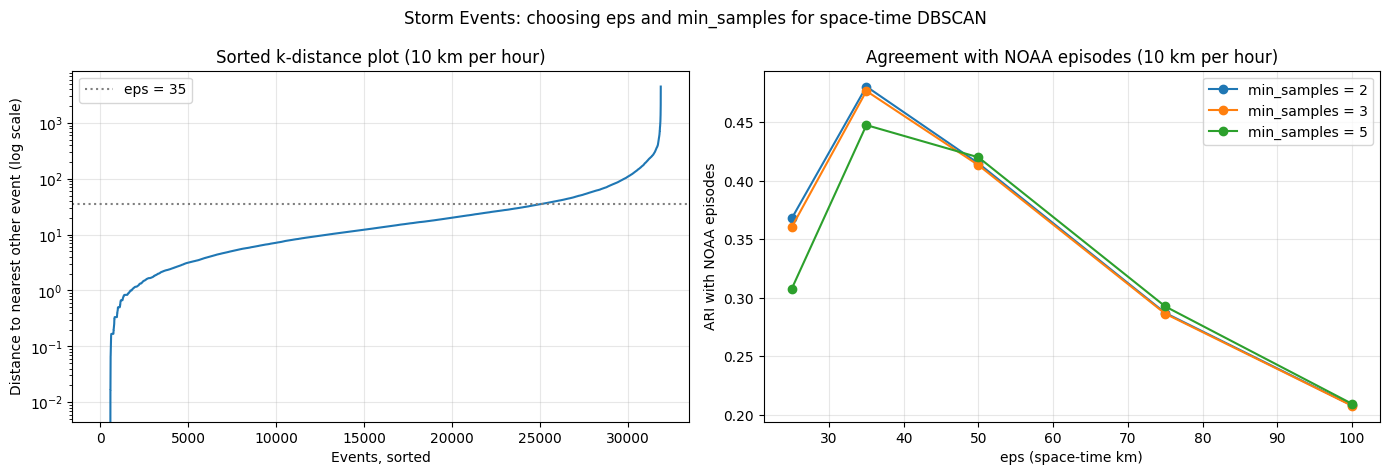

In [3]:
# Each speed (km per hour) sets how many km of distance one hour apart is worth
grid_rows, results = [], {}
for sp in [10, 25, 50]:
    Zst = np.c_[data['eastKm'], data['northKm'], data['hours'] * sp]
    for eps in [25, 35, 50, 75, 100]:
        for ms in [2, 3, 5]:
            lab = DBSCAN(eps=eps, min_samples=ms).fit(Zst).labels_
            results[(sp, eps, ms)] = lab
            in_cluster = lab >= 0
            offices = data.loc[in_cluster, 'WFO'].groupby(lab[in_cluster]).nunique()
            # Each noise event is its own group when comparing with episodes
            grid_rows.append({'km per hour': sp, 'eps (km)': eps, 'min_samples': ms, 'Clusters': int(lab.max() + 1),
                              'Noise share': 1 - in_cluster.mean(),
                              'ARI with NOAA episodes': adjusted_rand_score(data['EPISODE_ID'],
                                                                            np.where(in_cluster, lab, -np.arange(len(lab)) - 1)),
                              'Clusters spanning 2+ offices': (offices > 1).mean()})
grid = pd.DataFrame(grid_rows)
best_row = grid.loc[grid['ARI with NOAA episodes'].idxmax()]
print()
print(grid.sort_values('ARI with NOAA episodes', ascending=False).head(12).round(3).to_string(index=False))
print('\nHighest agreement with episodes:', best_row[['km per hour', 'eps (km)', 'min_samples']].to_dict())

# Sorted k-distance plot at the chosen speed, distance from each event to its nearest other event
sp_best, eps_best = int(best_row['km per hour']), int(best_row['eps (km)'])
ST = np.c_[data['eastKm'], data['northKm'], data['hours'] * sp_best]
kdist = NearestNeighbors(n_neighbors=2).fit(ST).kneighbors(ST)[0][:, -1]
print(f'Distance from each event to its nearest other event at {sp_best} km per hour, percentiles:')
print(pd.Series(np.percentile(kdist, [25, 50, 75, 90]), index=['25%', '50%', '75%', '90%']).round(1).to_string())
print(f'Share of events with another event within eps = {eps_best}: {(kdist <= eps_best).mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(np.sort(kdist))
axes[0].set_yscale('log')
axes[0].axhline(eps_best, color='gray', linestyle=':', label=f'eps = {eps_best}')
axes[0].set_xlabel('Events, sorted')
axes[0].set_ylabel('Distance to nearest other event (log scale)')
axes[0].set_title(f'Sorted k-distance plot ({sp_best} km per hour)')
axes[0].legend()
axes[0].grid(alpha=0.3)
sub = grid[(grid['km per hour'] == sp_best)]
for ms in [2, 3, 5]:
    s = sub[sub['min_samples'] == ms]
    axes[1].plot(s['eps (km)'], s['ARI with NOAA episodes'], marker='o', label=f'min_samples = {ms}')
axes[1].set_xlabel('eps (space-time km)')
axes[1].set_ylabel('ARI with NOAA episodes')
axes[1].set_title(f'Agreement with NOAA episodes ({sp_best} km per hour)')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.suptitle('Storm Events: choosing eps and min_samples for space-time DBSCAN')
plt.tight_layout()
plt.show()

The best agreement with NOAA's episodes comes at 10 km per hour, `eps` = 35, and `min_samples` = 2 (ARI 0.481), with 4,471 clusters and 21.5% of events as noise. The ARI curve peaks at `eps` = 35 for every `min_samples`. Smaller values break storms into fragments, larger values merge separate storms, and by `eps` = 100 the ARI falls to about 0.21. The k-distance plot shows the same thing from the data's side. The median event has another event within 13.5 space-time km, 78.5% have one within 35, and the curve turns sharply upward past about 100, where the isolated events begin.

An ARI of 0.48 means DBSCAN's storms and NOAA's episodes overlap but are not the same. The last column shows one reason. Even at the best setting, 12.4% of DBSCAN clusters contain events from two or more forecast offices, which no NOAA episode ever does.

### Storms that cross office boundaries

DBSCAN with 10 km per hour, eps = 35, min_samples = 2
        events               start                 end  offices  episodes  states  damageShare            topType
dbscan                                                                                                           
86         237 2017-03-01 01:00:00 2017-03-01 13:00:00        4         9       4     0.670886  Thunderstorm Wind
29         190 2017-05-17 13:35:00 2017-05-17 22:15:00        5         6       2     0.273684  Thunderstorm Wind
113        171 2017-03-01 04:08:00 2017-03-01 08:56:00        4         8       5     0.853801  Thunderstorm Wind
715        131 2017-05-27 11:15:00 2017-05-27 21:02:00        6         9       4     0.587786  Thunderstorm Wind
2546       115 2017-07-19 14:55:00 2017-07-19 19:56:00        5         9       4     0.626087  Thunderstorm Wind
812        112 2017-05-01 12:40:00 2017-05-01 21:12:00        4         8       2     0.794643  Thunderstorm Wind
108        112 2017-06-11 06:00:00

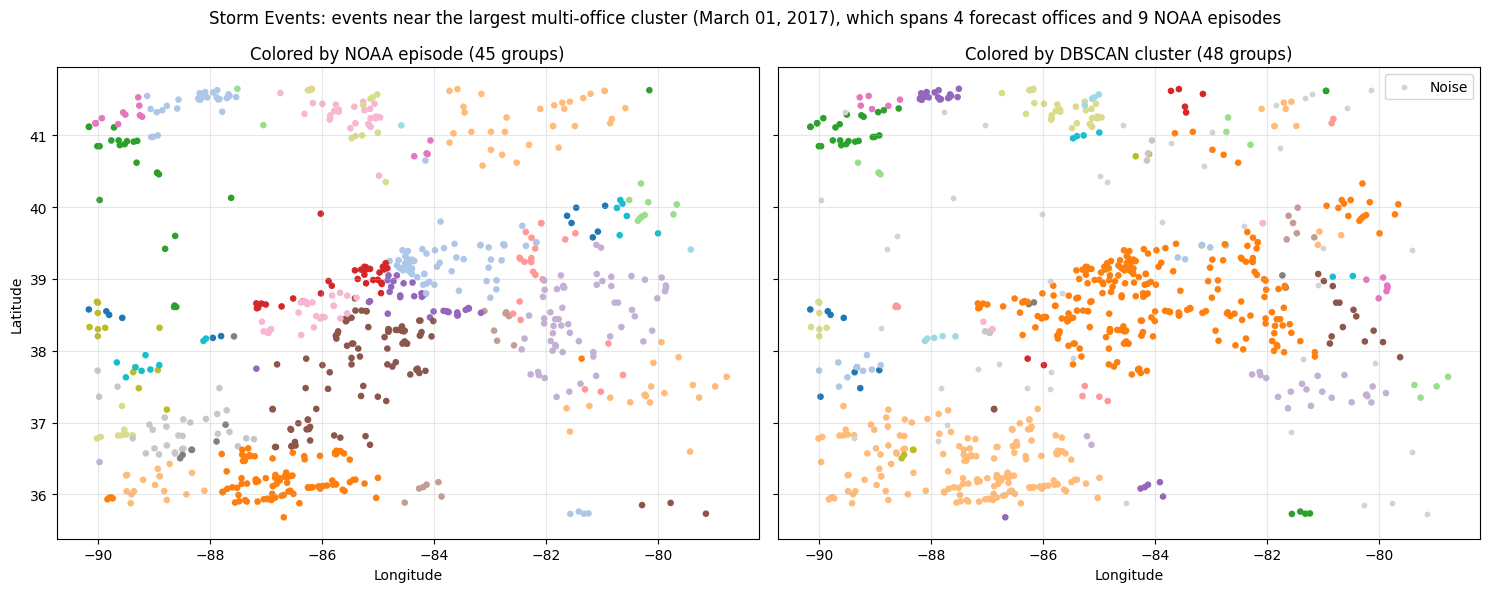

In [4]:
sp, eps, ms = int(best_row['km per hour']), int(best_row['eps (km)']), int(best_row['min_samples'])
data['dbscan'] = results[(sp, eps, ms)]
clustered = data[data['dbscan'] >= 0]
storms = clustered.groupby('dbscan').agg(events=('damaged', 'size'), start=('begin', 'min'), end=('begin', 'max'),
                                         offices=('WFO', 'nunique'), episodes=('EPISODE_ID', 'nunique'),
                                         states=('STATE', 'nunique'), damageShare=('damaged', 'mean'),
                                         topType=('EVENT_TYPE', lambda s: s.value_counts().index[0]))
print(f'DBSCAN with {sp} km per hour, eps = {eps}, min_samples = {ms}')
print(storms.sort_values('events', ascending=False).head(8).to_string())
print(f'\nClusters that combine 2 or more NOAA episodes: {(storms["episodes"] > 1).mean():.3f}'
      f' | of those, share spanning 2 or more offices: {(storms.loc[storms["episodes"] > 1, "offices"] > 1).mean():.3f}')
print(f'Damage share, events in clusters: {clustered["damaged"].mean():.3f} | noise events: '
      f'{data.loc[data["dbscan"] == -1, "damaged"].mean():.3f}')
print('Most common event types among noise events:')
print(data.loc[data['dbscan'] == -1, 'EVENT_TYPE'].value_counts().head(5).to_string())

# Picture the largest multi-office cluster, colored by NOAA episode and by DBSCAN cluster
big = storms[storms['offices'] > 1].sort_values('events', ascending=False).index[0]
window = data[(data['begin'] >= storms.loc[big, 'start'] - pd.Timedelta(hours=12)) &
              (data['begin'] <= storms.loc[big, 'end'] + pd.Timedelta(hours=12))]
lon_lim = (data.loc[data['dbscan'] == big, 'BEGIN_LON'].min() - 3, data.loc[data['dbscan'] == big, 'BEGIN_LON'].max() + 3)
lat_lim = (data.loc[data['dbscan'] == big, 'BEGIN_LAT'].min() - 2, data.loc[data['dbscan'] == big, 'BEGIN_LAT'].max() + 2)
window = window[window['BEGIN_LON'].between(*lon_lim) & window['BEGIN_LAT'].between(*lat_lim)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, col, title in [(axes[0], 'EPISODE_ID', 'Colored by NOAA episode'), (axes[1], 'dbscan', 'Colored by DBSCAN cluster')]:
    codes = pd.factorize(window[col])[0]
    noise_pts = window[col].values == -1 if col == 'dbscan' else np.zeros(len(window), bool)
    ax.scatter(window.loc[~noise_pts, 'BEGIN_LON'], window.loc[~noise_pts, 'BEGIN_LAT'], c=codes[~noise_pts] % 20,
               cmap='tab20', s=14)
    ax.scatter(window.loc[noise_pts, 'BEGIN_LON'], window.loc[noise_pts, 'BEGIN_LAT'], color='lightgray', s=10, label='Noise')
    ax.set_title(f'{title} ({window[col][window[col] != -1].nunique()} groups)')
    ax.set_xlabel('Longitude')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Latitude')
axes[1].legend()
fig.suptitle(f'Storm Events: events near the largest multi-office cluster ({storms.loc[big, "start"]:%B %d, %Y}), '
             f'which spans {storms.loc[big, "offices"]} forecast offices and {storms.loc[big, "episodes"]} NOAA episodes')
plt.tight_layout()
plt.show()

At the chosen setting, 23.1% of DBSCAN clusters combine two or more NOAA episodes, and more than half of those (53.7%) span two or more forecast offices. The largest clusters are single-day outbreaks of severe weather. The biggest, on March 1, 2017, holds 237 events from 4 offices, 9 NOAA episodes, and 4 states, and the figure shows it. NOAA split the storm into many episodes, while DBSCAN joins much of it into one band of thunderstorm wind reports, and another of the largest clusters, on May 27, spans 6 offices.

Events that DBSCAN labels as noise report damage less often (31.3% against 35.7% in clusters). They are mostly isolated thunderstorm wind, hail, and flood reports, single events with no other event nearby in place and time.

## Part B - Hierarchical clustering of event types

HAC needs every pairwise distance and produces one leaf per point, so it suits small sets best. This part clusters event types instead of events. Each type with at least 30 events in 2017 is described by its share of events with damage, its share with any injury or death, its mean log duration, its average season (the mean sine and cosine of the day of the year), and the share of its events reported with a point location instead of a county or forecast zone. All 2017 events with a damage entry are used here, including zone-based ones such as winter storms and heat, which have no coordinates. The next cell compares the four linkage methods and draws the Ward and single-linkage dendrograms.

Event types with 30 or more events: 36
 Linkage  Cophenetic correlation Cluster sizes at 5 clusters  Silhouette at 5 clusters  Clusters with one type
  single                   0.801           [16, 12, 6, 1, 1]                     0.359                       2
complete                   0.776           [19, 12, 2, 2, 1]                     0.328                       1
 average                   0.892           [16, 12, 5, 2, 1]                     0.386                       1
    ward                   0.678           [17, 12, 4, 2, 1]                     0.389                       1
Cluster 1 (damage share 0.25, casualty share 0.020, median hours 0.3): Thunderstorm Wind, Hail, Flash Flood, Flood, Tornado, Marine Thunderstorm Wind, Heavy Rain, Lightning, Funnel Cloud, Debris Flow, Waterspout, Marine High Wind
Cluster 2 (damage share 0.17, casualty share 0.024, median hours 12.4): High Wind, Winter Weather, Winter Storm, Heavy Snow, Strong Wind, Drought, Dense Fog, High Surf, Frost/F

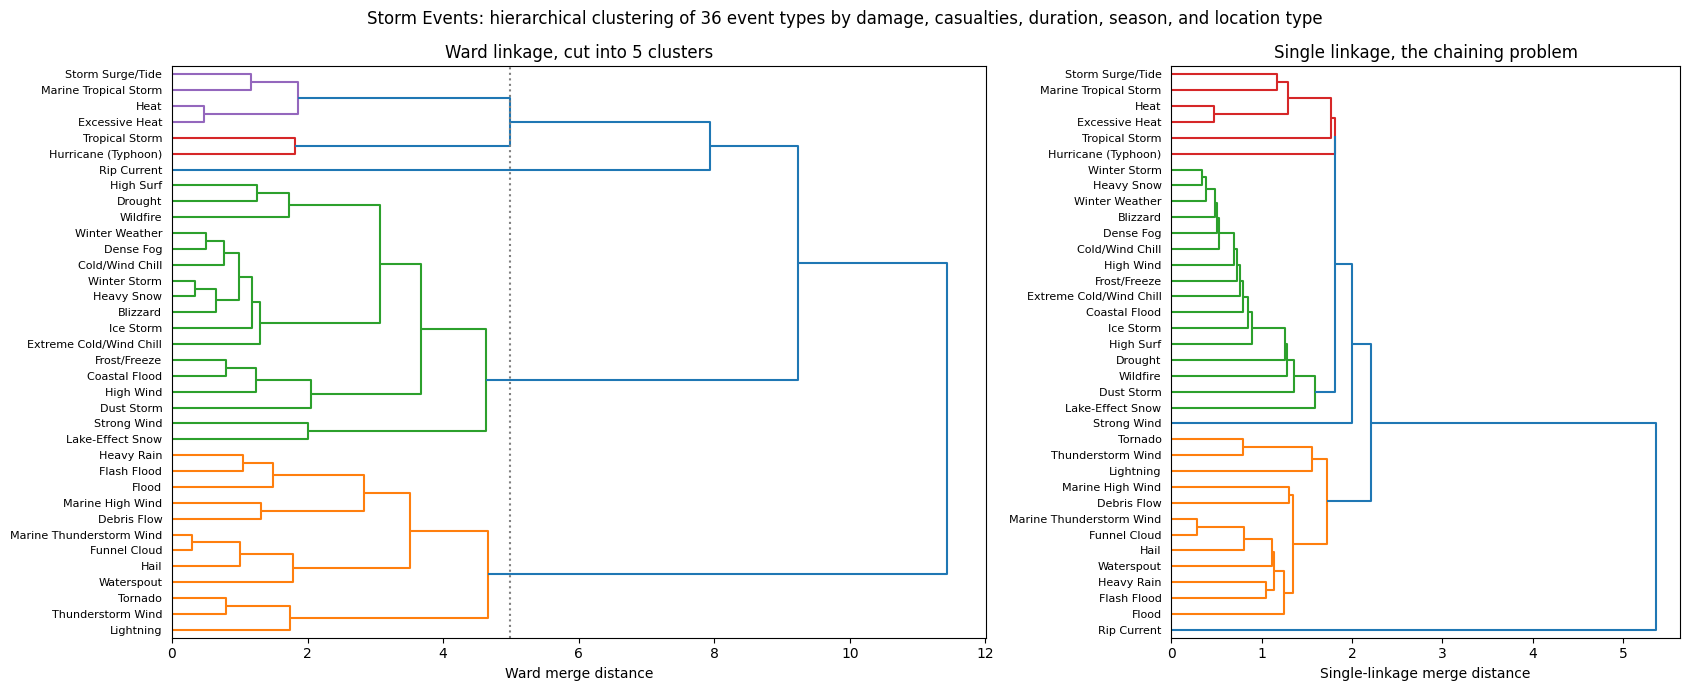

In [5]:
# One profile per event type, using every 2017 event with a damage entry (including zone-based events without coordinates)
types = df.dropna(subset=['damageProperty', 'begin']).copy()
types['damaged'] = (types['damageProperty'] > 0).astype(int)
types['hurt'] = ((types[['INJURIES_DIRECT', 'INJURIES_INDIRECT', 'DEATHS_DIRECT', 'DEATHS_INDIRECT']].sum(axis=1)) > 0).astype(int)
types['logDuration'] = np.log10(types['durationHours'] + 0.1)
angle = 2 * np.pi * types['begin'].dt.dayofyear / 365.25
types['seasonSin'], types['seasonCos'] = np.sin(angle), np.cos(angle)
profiles = types.groupby('EVENT_TYPE').agg(events=('damaged', 'size'), damageShare=('damaged', 'mean'),
                                           casualtyShare=('hurt', 'mean'), logDuration=('logDuration', 'mean'),
                                           seasonSin=('seasonSin', 'mean'), seasonCos=('seasonCos', 'mean'),
                                           pointLocated=('BEGIN_LAT', lambda s: s.notna().mean()))
profiles = profiles[profiles['events'] >= 30]
type_features = ['damageShare', 'casualtyShare', 'logDuration', 'seasonSin', 'seasonCos', 'pointLocated']
Zt = StandardScaler().fit_transform(profiles[type_features])
print('Event types with 30 or more events:', len(profiles))

link_rows, links = [], {}
for method in ['single', 'complete', 'average', 'ward']:
    L = linkage(Zt, method=method)
    links[method] = L
    coph, _ = cophenet(L, pdist(Zt))
    lab = fcluster(L, 5, criterion='maxclust')
    sizes = sorted(np.bincount(lab)[1:].tolist(), reverse=True)
    link_rows.append({'Linkage': method, 'Cophenetic correlation': coph, 'Cluster sizes at 5 clusters': sizes,
                      'Silhouette at 5 clusters': silhouette_score(Zt, lab),
                      'Clusters with one type': sum(s == 1 for s in sizes)})
print(pd.DataFrame(link_rows).round(3).to_string(index=False))

n_clusters = 5
profiles['wardCluster'] = fcluster(links['ward'], n_clusters, criterion='maxclust')
for c, grp in profiles.groupby('wardCluster'):
    print(f'Cluster {c} (damage share {grp["damageShare"].mean():.2f}, casualty share {grp["casualtyShare"].mean():.3f}, '
          f'median hours {10 ** grp["logDuration"].mean() - 0.1:.1f}): {", ".join(grp.sort_values("events", ascending=False).index)}')

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.6, 1]})
L = links['ward']
dendrogram(L, labels=profiles.index.tolist(), orientation='right', leaf_font_size=8,
           color_threshold=L[-(n_clusters - 1), 2], ax=axes[0])
axes[0].axvline(L[-(n_clusters - 1), 2], color='gray', linestyle=':')
axes[0].set_xlabel('Ward merge distance')
axes[0].set_title(f'Ward linkage, cut into {n_clusters} clusters')
dendrogram(links['single'], labels=profiles.index.tolist(), orientation='right', leaf_font_size=8,
           color_threshold=links['single'][-(n_clusters - 1), 2], ax=axes[1])
axes[1].set_xlabel('Single-linkage merge distance')
axes[1].set_title('Single linkage, the chaining problem')
fig.suptitle(f'Storm Events: hierarchical clustering of {len(profiles)} event types by damage, casualties, duration, season, and location type')
plt.tight_layout()
plt.show()

Ward linkage cut into five clusters gives a clear grouping of the 36 event types.

- **Convective and flood events** (12 types), such as thunderstorm wind, hail, tornadoes, and flash floods. They are short, typically well under an hour as recorded, point-located, and report damage 25% of the time.
- **Winter, wind, and dry-weather events** (17 types), such as winter storms, high wind, drought, and wildfire. They typically last about half a day, are recorded by zone, and report damage 17% of the time.
- **Tropical storms and hurricanes**, which report damage 83% of the time and some casualty 17% of the time.
- **Heat and storm surge** (4 types), long events that rarely report property damage in these records (8%).
- **Rip currents**, alone, with no property damage but a casualty in 91% of reports.

The linkage methods differ less here than for the NFIP counties, since these types form fairly separate groups. All four linkages have silhouettes between 0.33 and 0.39 at five clusters, and average linkage has the highest cophenetic correlation (0.892). The dendrograms still show the chaining effect of single linkage. It joins the winter weather types one at a time in a long staircase, and its top split separates rip currents from everything else, which tells nothing about the other 35 types.

### Stability

The last cell checks whether the clusters hold up when the data changes, by refitting Ward linkage without a random 10% of the event types and rerunning DBSCAN on random 80% subsamples of events.

In [6]:
# Stability of the Ward clusters, drop 10% of event types at random and refit
rng = np.random.RandomState(0)
ari = []
for _ in range(20):
    keep = rng.rand(len(Zt)) > 0.1
    sub = fcluster(linkage(Zt[keep], 'ward'), n_clusters, criterion='maxclust')
    ari.append(adjusted_rand_score(profiles['wardCluster'].values[keep], sub))
print(f'Ward clusters after dropping 10% of event types (20 repeats): ARI median {np.median(ari):.3f}, min {min(ari):.3f}')

# Stability of DBSCAN, rerun on a random 80% of events and compare labels on the shared events
ari_db = []
Zbest = np.c_[data['eastKm'], data['northKm'], data['hours'] * sp]
for seed in range(5):
    keep = np.random.RandomState(seed).rand(len(data)) < 0.8
    sub = DBSCAN(eps=eps, min_samples=ms).fit(Zbest[keep]).labels_
    full = data['dbscan'].values[keep]
    ari_db.append(adjusted_rand_score(np.where(full >= 0, full, -np.arange(keep.sum()) - 1),
                                      np.where(sub >= 0, sub, -np.arange(keep.sum()) - 1)))
print(f'DBSCAN on 80% subsamples (5 repeats): ARI with the full-data clusters, median {np.median(ari_db):.3f}, min {min(ari_db):.3f}')

Ward clusters after dropping 10% of event types (20 repeats): ARI median 0.862, min 0.596


DBSCAN on 80% subsamples (5 repeats): ARI with the full-data clusters, median 0.875, min 0.860


The Ward clusters of event types are stable. Dropping 10% of the types at random gives a median ARI of 0.862 with the full clusters (minimum 0.596). DBSCAN is also stable. On random 80% subsamples, its clusters agree with the full-data clusters at a median ARI of 0.875 (minimum 0.860), although removing events can only split or shrink clusters, since density can only fall.

## Discussion

### Overfitting

Without a target, the risk is tuning DBSCAN until it reproduces a pattern that exists only in this sample. Three things guarded against that. The settings were compared across a whole grid against an outside reference, NOAA's episodes, which the clustering never saw, and the best setting sits on a clear peak with similar ARIs for every `min_samples`. The k-distance plot gave an independent check on `eps`, and the subsample check showed the clusters reappearing in 80% samples (median ARI 0.875). For HAC, comparing four linkages and refitting without 10% of the event types (median ARI 0.862) showed that the five-cluster Ward grouping is not an accident of one method or one set of types.

### Metrics and hyperparameter tuning

DBSCAN has three choices here. `eps` = 35 is the neighborhood radius in space-time km, `min_samples` = 2 means any two events that close together form a storm, and the speed of 10 km per hour sets how much an hour apart counts against a kilometer apart, so `eps` = 35 means 35 km at the same moment or 3.5 hours at the same place. They were chosen by the ARI with NOAA's episodes, with the noise share and the k-distance plot as checks. For HAC, the linkage method and the number of clusters were chosen by the cophenetic correlation (how faithfully the tree keeps the original distances, 0.678 to 0.892), the silhouette at five clusters (0.33 to 0.39), the cluster sizes, and the dendrograms, with the cut placed where the Ward merge distances jump.

### Expected or unexpected

I expected DBSCAN to recover NOAA's episodes closely. It did not (ARI 0.48), and the reason was the most interesting result of the week. NOAA's episodes never cross a forecast office boundary, while storms do, and DBSCAN joined episodes from as many as 6 offices into one storm. This connects to Weeks 4 to 9, where the reporting office was one of the strongest predictors of damage reports. The episodes, like the damage entries, are partly a record of who did the reporting. On the HAC side, rip currents standing alone and storm surge grouping with heat were unexpected, though both make sense once the profiles are read. Rip currents almost never cause property damage but often cause casualties, and storm surge and heat are both long, zone-based events with little reported property damage in these records.

### How EDA helped

The episode analysis from Week 4 (64% of multi-event episodes share one damage label) and the Week 8 result that two thirds of events have a sibling from their own episode as nearest neighbor are what made the comparison with episodes worth running. The Week 4 finding that reporting offices differ sharply in how they record damage suggested checking office boundaries, which explained much of the disagreement. For HAC, the Module B finding that many event types are recorded by zone, without coordinates, is why the share of point-located events is part of each type's profile.

### External sources

- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)*, 226-231.
- Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited. Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems*, 42(3), 1-21.
- scikit-learn User Guide, "Clustering," the sections on DBSCAN and hierarchical clustering: https://scikit-learn.org/stable/modules/clustering.html
- SciPy documentation, `scipy.cluster.hierarchy.linkage`, which defines the single, complete, average, and Ward linkage methods: https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html

### Conclusions

Space-time DBSCAN rebuilds storm systems from single events and agrees with NOAA's episodes only partly (ARI 0.481 at 10 km per hour, `eps` = 35, `min_samples` = 2). The disagreement is informative. 23% of DBSCAN's storms join several NOAA episodes, and more than half of those cross forecast office boundaries, which NOAA's episodes never do. Hierarchical clustering sorts the 36 common event types into five stable groups (median ARI 0.862 under resampling), with tropical storms and hurricanes standing apart as the only group where most events report damage.

For Milestone Two and the Capstone, the main lesson is that NOAA's episodes are a reporting unit, not a physical storm. Grouping validation by DBSCAN storms instead of episodes would be a stricter test for the supervised models of Weeks 4 to 9, since it would stop a storm's events in different offices from landing on both sides of a split.